# Redshift-coded UMAP plots

Reuses the Variant A (22-feat, `build_feature_matrix`) UMAP embedding from `analysis.ipynb` -- same pipeline, same `fit_umap` defaults (`n_neighbors=15, min_dist=0.1, n_components=2, random_state=42`), re-executed here since the embedding isn't persisted anywhere in the repo (checked: no `.npy`/`np.save`/`joblib.dump` for it anywhere). Not refit with different parameters. Persists the embedding to `data/processed/` at the end of this notebook so future tasks don't need to recompute it again. See `results/REDSHIFT_PLOTS.md` for the full writeup.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

import numpy as np
from sklearn.preprocessing import StandardScaler

from src import preprocessing
from src.conversions import ZERO_POINT_JY, build_feature_matrix, combine_first_column
from src.clustering import fit_umap
from src.plots import plot_embedding_by_value

DATA_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")

## Load, label, and rebuild the Variant A embedding (same as `analysis.ipynb`)

In [2]:
df = preprocessing.load_catalog(DATA_DIR / "Multiwave_UMAP_6_26_26.csv")
df = preprocessing.merge_csc_spectral_fits(df, DATA_DIR / "csc_spec_fits.csv")
df = preprocessing.merge_desi(df, DATA_DIR / "Multiwave_7_8_26.csv")
df = preprocessing.clean_types(df)
df = preprocessing.mask_magnitude_sentinels(df, ZERO_POINT_JY)
df = combine_first_column(df, "PS21P_g", "LEG21P_G", "combo_g")
df = combine_first_column(df, "PS21P_r", "LEG21P_R", "combo_r")
df = combine_first_column(df, "PS21P_z", "LEG21P_Z", "combo_z_mag")
df = preprocessing.build_labels(df)
print(f"Loaded and labeled: {df.shape}")

C:\dev\ml-directory\projects\astro\src\preprocessing.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return df.merge(spec, on="name", how="left", validate="many_to_one")


Loaded and labeled: (170196, 208)


In [3]:
# Identical to analysis.ipynb's Variant A cells: build_feature_matrix -> StandardScaler -> fit_umap(X_scaled)
# with no overrides (same n_neighbors=15, min_dist=0.1, n_components=2, random_state=42 as the source notebook).
df_sample, X = build_feature_matrix(df)
print(f"Variant A df_sample/X shape: {df_sample.shape}, {X.shape}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
embedding = fit_umap(X_scaled)
print("UMAP embedding shape:", embedding.shape)

Variant A df_sample/X shape: (25801, 211), (25801, 22)


C:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (25801, 2)


In [4]:
# Not persisted anywhere in the repo before this notebook (checked: no .npy / np.save / joblib.dump
# for a UMAP embedding anywhere). Saving now so future tasks can reuse it without recomputing.
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
np.save(PROCESSED_DIR / "umap_embedding_reduced_22feat.npy", embedding)
np.save(PROCESSED_DIR / "umap_embedding_reduced_22feat_index.npy", df_sample.index.to_numpy())
print(f"Saved embedding to {PROCESSED_DIR / 'umap_embedding_reduced_22feat.npy'} and its row index alongside it.")

Saved embedding to ..\data\processed\umap_embedding_reduced_22feat.npy and its row index alongside it.


## Redshift + label subsets

Canonical redshift column per `STATE.md` §5: `combo_Z` gated by `high_quality_z` (booleanized via `to_bool_safe`, matching how `build_labels` itself uses this gate for the silver-score's redshift component).

In [5]:
import pandas as pd

combo_z = pd.to_numeric(df_sample["combo_Z"], errors="coerce")
has_z = (combo_z > 0) & preprocessing.to_bool_safe(df_sample["high_quality_z"])
print(f"Rows with valid high-quality combo_Z (within the {len(df_sample)}-row Variant A sample): {has_z.sum()}")

label_3class = df_sample["label_3class"]
gold_mask = label_3class.isin([0, 2])
agn_mask = label_3class == 2
nonagn_mask = label_3class == 0

gold_z_mask = (gold_mask & has_z).to_numpy()
agn_z_mask = (agn_mask & has_z).to_numpy()

print(f"Gold (label_3class in {{0,2}}): {gold_mask.sum()} | Gold with valid z: {gold_z_mask.sum()}")
print(f"Gold AGN (label_3class==2): {agn_mask.sum()} | Gold AGN with valid z: {agn_z_mask.sum()}")
print(f"Gold non-AGN (label_3class==0): {nonagn_mask.sum()} | Gold non-AGN with valid z: {(nonagn_mask & has_z).sum()}")

is_agn_shape = (label_3class == 2).to_numpy()

Rows with valid high-quality combo_Z (within the 25801-row Variant A sample): 9992
Gold (label_3class in {0,2}): 13115 | Gold with valid z: 9992
Gold AGN (label_3class==2): 12272 | Gold AGN with valid z: 9992
Gold non-AGN (label_3class==0): 843 | Gold non-AGN with valid z: 0


## Figure 1 -- gold only, colored by redshift

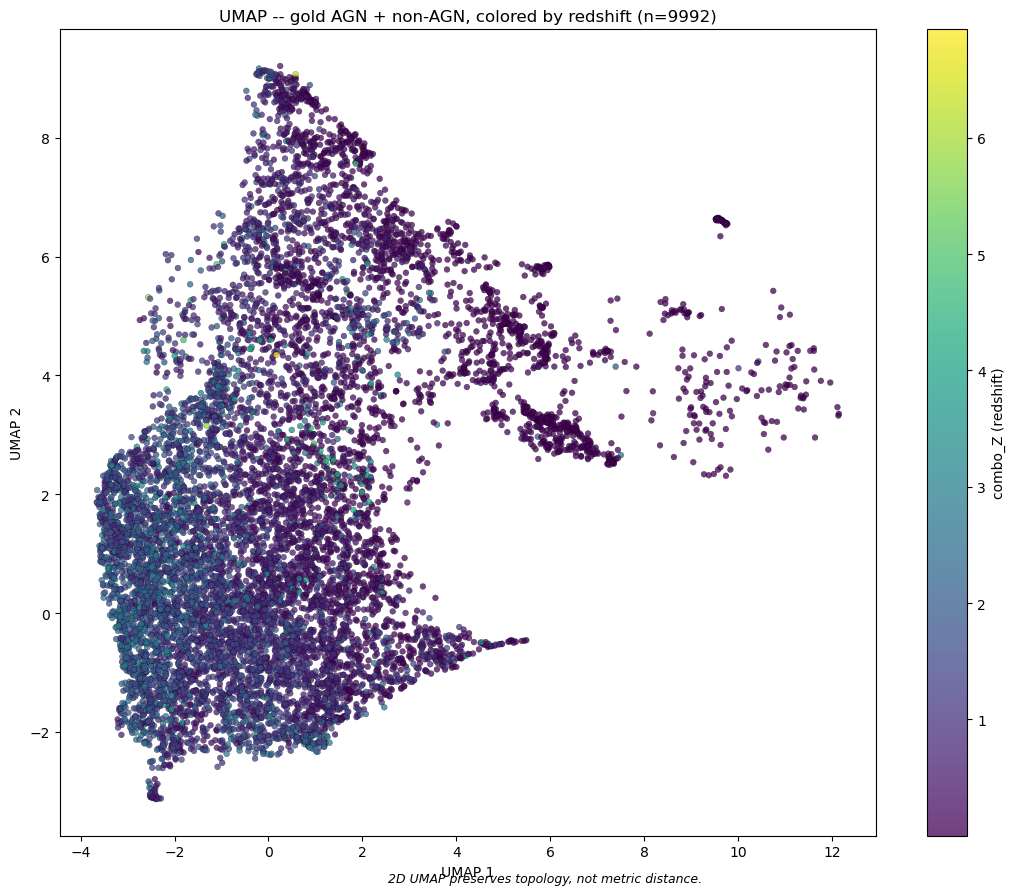

(<Figure size 1100x900 with 2 Axes>,
 <Axes: title={'center': 'UMAP -- gold AGN + non-AGN, colored by redshift (n=9992)'}, xlabel='UMAP 1', ylabel='UMAP 2'>)

In [6]:
plot_embedding_by_value(
    embedding, combo_z.to_numpy(), gold_z_mask,
    value_label="combo_Z (redshift)",
    title="UMAP -- gold AGN + non-AGN, colored by redshift",
    caption="2D UMAP preserves topology, not metric distance.",
    save_path=RESULTS_DIR / "figures" / "reduced_22feat" / "umap_redshift_gold_only.png",
)

## Figure 2 -- gold AGN only, size AND color both encode redshift

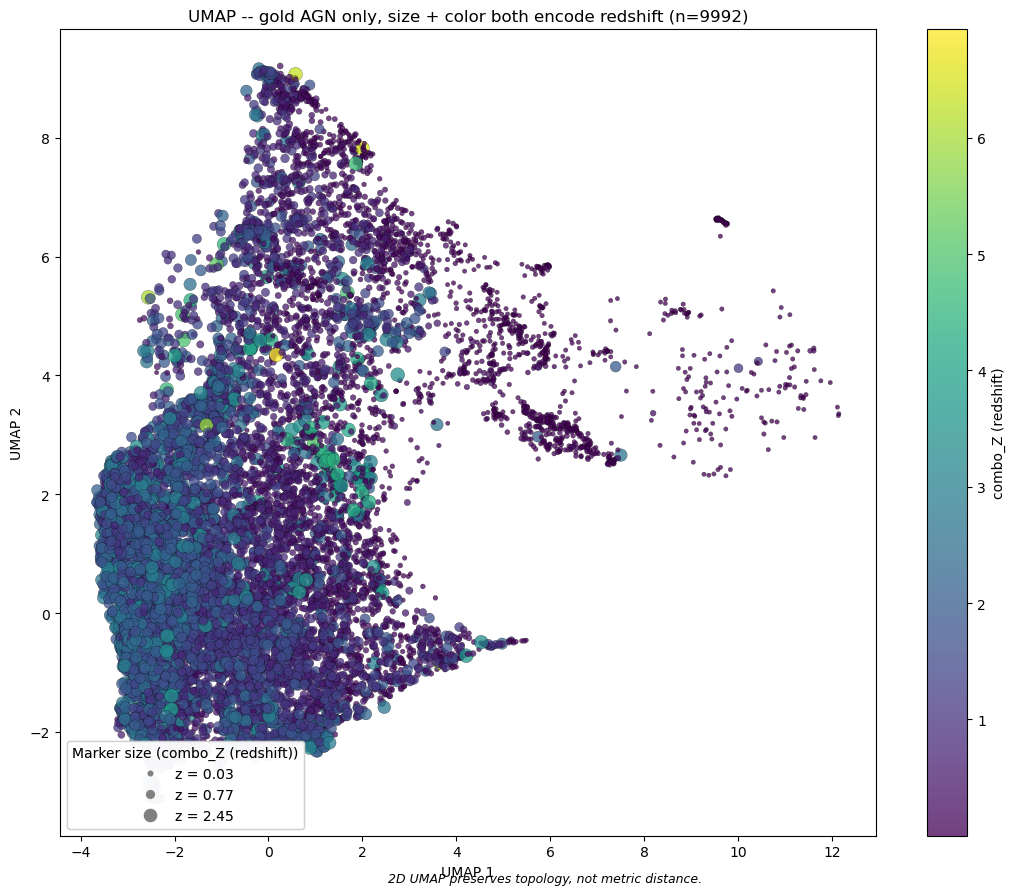

(<Figure size 1100x900 with 2 Axes>,
 <Axes: title={'center': 'UMAP -- gold AGN only, size + color both encode redshift (n=9992)'}, xlabel='UMAP 1', ylabel='UMAP 2'>)

In [7]:
z_agn_only = combo_z.to_numpy()[agn_z_mask]
size_legend_values = list(np.percentile(z_agn_only, [5, 50, 95]))

plot_embedding_by_value(
    embedding, combo_z.to_numpy(), agn_z_mask, size_col=combo_z.to_numpy(),
    value_label="combo_Z (redshift)",
    title="UMAP -- gold AGN only, size + color both encode redshift",
    caption="2D UMAP preserves topology, not metric distance.",
    size_legend_values=size_legend_values,
    save_path=RESULTS_DIR / "figures" / "reduced_22feat" / "umap_redshift_agn_only_size.png",
)

## Figure 3 -- gold AGN vs. non-AGN, color = redshift, shape = AGN/non-AGN

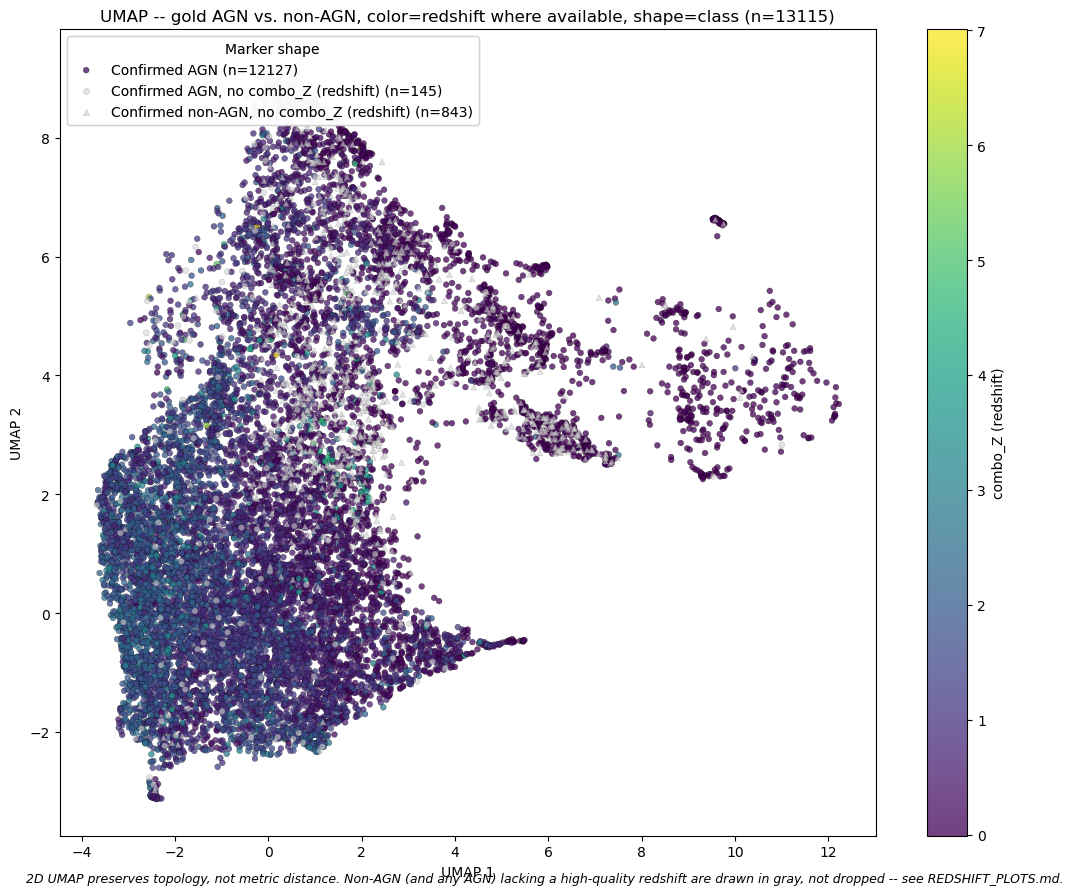

(<Figure size 1100x900 with 2 Axes>,
 <Axes: title={'center': 'UMAP -- gold AGN vs. non-AGN, color=redshift where available, shape=class (n=13115)'}, xlabel='UMAP 1', ylabel='UMAP 2'>)

In [8]:
gold_all_mask = gold_mask.to_numpy()  # AGN and non-AGN both included, regardless of z coverage
plot_embedding_by_value(
    embedding, combo_z.to_numpy(), gold_all_mask, shape_col=is_agn_shape,
    value_label="combo_Z (redshift)",
    title="UMAP -- gold AGN vs. non-AGN, color=redshift where available, shape=class",
    caption="2D UMAP preserves topology, not metric distance. Non-AGN (and any AGN) lacking a "
            "high-quality redshift are drawn in gray, not dropped -- see REDSHIFT_PLOTS.md.",
    shape_labels=("Confirmed AGN", "Confirmed non-AGN"),
    shape_markers=("o", "^"),
    save_path=RESULTS_DIR / "figures" / "reduced_22feat" / "umap_redshift_agn_vs_nonagn.png",
)

## Redshift structure diagnostics

Quantitative checks behind the qualitative "gradient / clustering / compression" read of the figures above.

In [9]:
from scipy.stats import pearsonr

z_gold = combo_z.to_numpy()[gold_z_mask]
emb_gold = embedding[gold_z_mask]
r1, p1 = pearsonr(emb_gold[:, 0], z_gold)
r2, p2 = pearsonr(emb_gold[:, 1], z_gold)
print(f"Pearson r(UMAP1, z) = {r1:.3f} (p={p1:.2e}) | Pearson r(UMAP2, z) = {r2:.3f} (p={p2:.2e})")

z_agn = combo_z.to_numpy()[(agn_mask & has_z).to_numpy()]
z_nonagn = combo_z.to_numpy()[(nonagn_mask & has_z).to_numpy()]
print(f"AGN z: median={np.median(z_agn):.3f}, IQR=({np.percentile(z_agn,25):.3f}, {np.percentile(z_agn,75):.3f})")
if len(z_nonagn) == 0:
    # Not a masking bug -- verified directly against the general 170,196-row catalog: every
    # single one of the 27,335 rows with valid combo_Z + high_quality_z is agn_positive.
    # agn_negative rows have combo_Z entirely missing (not just low-quality), catalog-wide.
    print(
        "non-AGN z: N/A -- zero gold non-AGN rows have a valid high-quality combo_Z, "
        "in this Variant A sample AND catalog-wide (verified against the full 170,196-row df: "
        "agn_negative & combo_Z.notna() == 0 rows). combo_Z's redshift cross-match appears to "
        "only ever attach to agn_positive sources in this catalog."
    )
else:
    print(f"non-AGN z: median={np.median(z_nonagn):.3f}, IQR=({np.percentile(z_nonagn,25):.3f}, {np.percentile(z_nonagn,75):.3f})")

# Are the highest-z AGN spatially concentrated relative to a random same-size AGN sample?
# Compare mean pairwise distance of the top decile (by z) against R random draws of the same size.
from scipy.spatial.distance import pdist

emb_agn = embedding[agn_z_mask]
z_vals = combo_z.to_numpy()[agn_z_mask]
top_decile_idx = np.argsort(z_vals)[-max(10, len(z_vals) // 10):]
top_decile_mean_dist = pdist(emb_agn[top_decile_idx]).mean()

rng = np.random.RandomState(42)
random_means = [
    pdist(emb_agn[rng.choice(len(emb_agn), size=len(top_decile_idx), replace=False)]).mean()
    for _ in range(200)
]
percentile_rank = (np.array(random_means) < top_decile_mean_dist).mean() * 100
print(
    f"Top-decile-by-z AGN (n={len(top_decile_idx)}) mean pairwise UMAP distance: {top_decile_mean_dist:.3f}\n"
    f"Random same-size AGN draws (n=200): mean={np.mean(random_means):.3f}, std={np.std(random_means):.3f}\n"
    f"Top-decile distance is at the {percentile_rank:.1f}th percentile of the random-draw distribution "
    f"(lower percentile => more spatially concentrated than a random same-size AGN sample; ~50th => indistinguishable from random)"
)

Pearson r(UMAP1, z) = -0.578 (p=0.00e+00) | Pearson r(UMAP2, z) = -0.303 (p=9.68e-211)
AGN z: median=0.766, IQR=(0.293, 1.419)
non-AGN z: N/A -- zero gold non-AGN rows have a valid high-quality combo_Z, in this Variant A sample AND catalog-wide (verified against the full 170,196-row df: agn_negative & combo_Z.notna() == 0 rows). combo_Z's redshift cross-match appears to only ever attach to agn_positive sources in this catalog.


Top-decile-by-z AGN (n=999) mean pairwise UMAP distance: 3.336
Random same-size AGN draws (n=200): mean=4.718, std=0.078
Top-decile distance is at the 0.0th percentile of the random-draw distribution (lower percentile => more spatially concentrated than a random same-size AGN sample; ~50th => indistinguishable from random)
